In [28]:

%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df = pd.read_csv("./samples.csv", quotechar="'")


df = df.iloc[1:].copy()

df["Elapsed time"] = pd.to_timedelta(
    "00:" + df["Elapsed time"].astype(str)
).dt.total_seconds()

df["ECG I"] = pd.to_numeric(df["ECG I"])
df["ECG I filtered"] = pd.to_numeric(df["ECG I filtered"])


## 1. The shape of the ECG signal can be more clearly seen after filtering than the original, and the peaks are significantly less sharp after filtering. A common possible artefact that is filtered is the 50Hz interference from the local powerline. There could also be minor noise from other sources such as the interference from local devices.

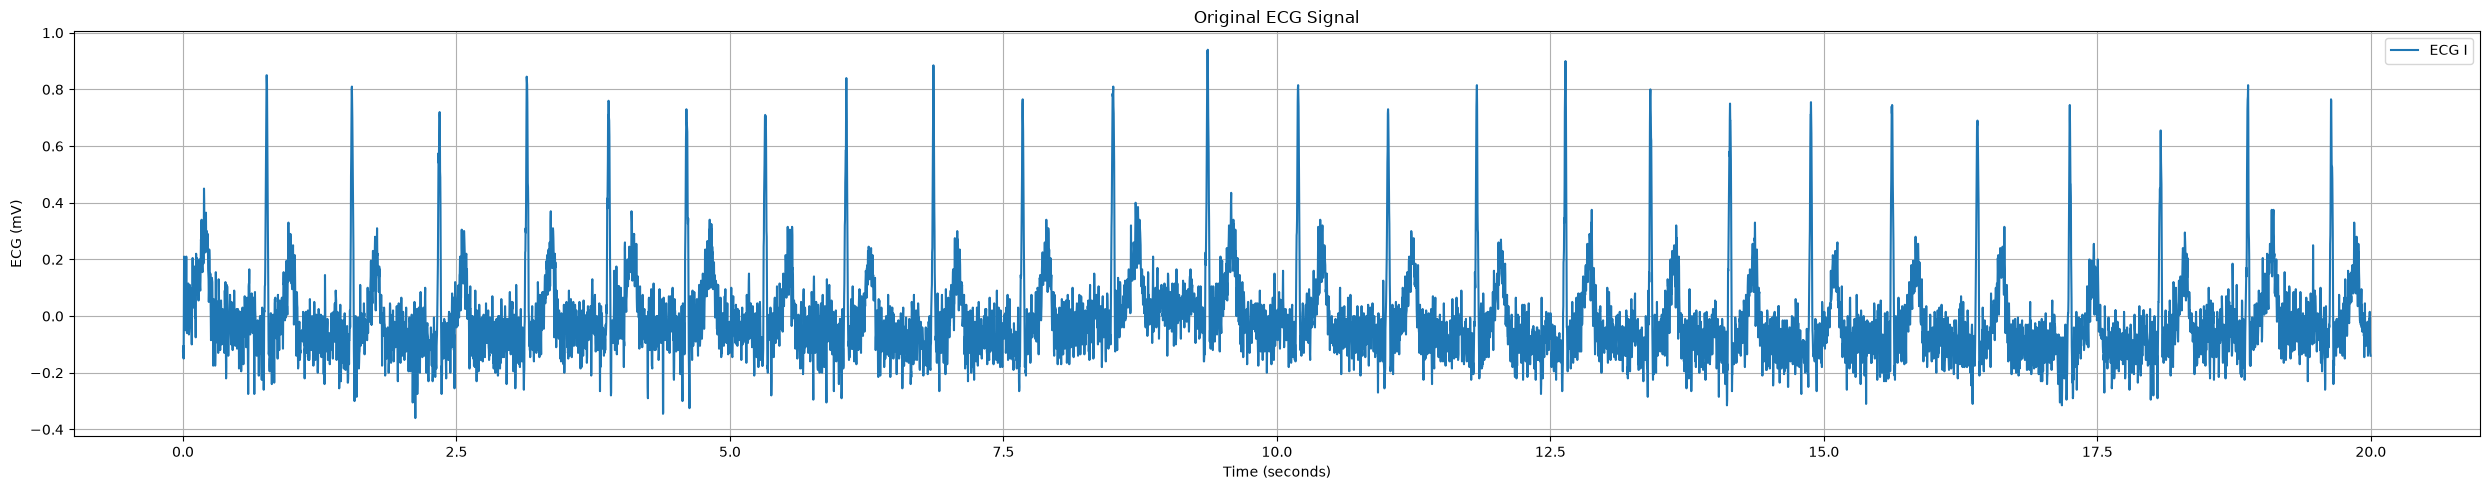

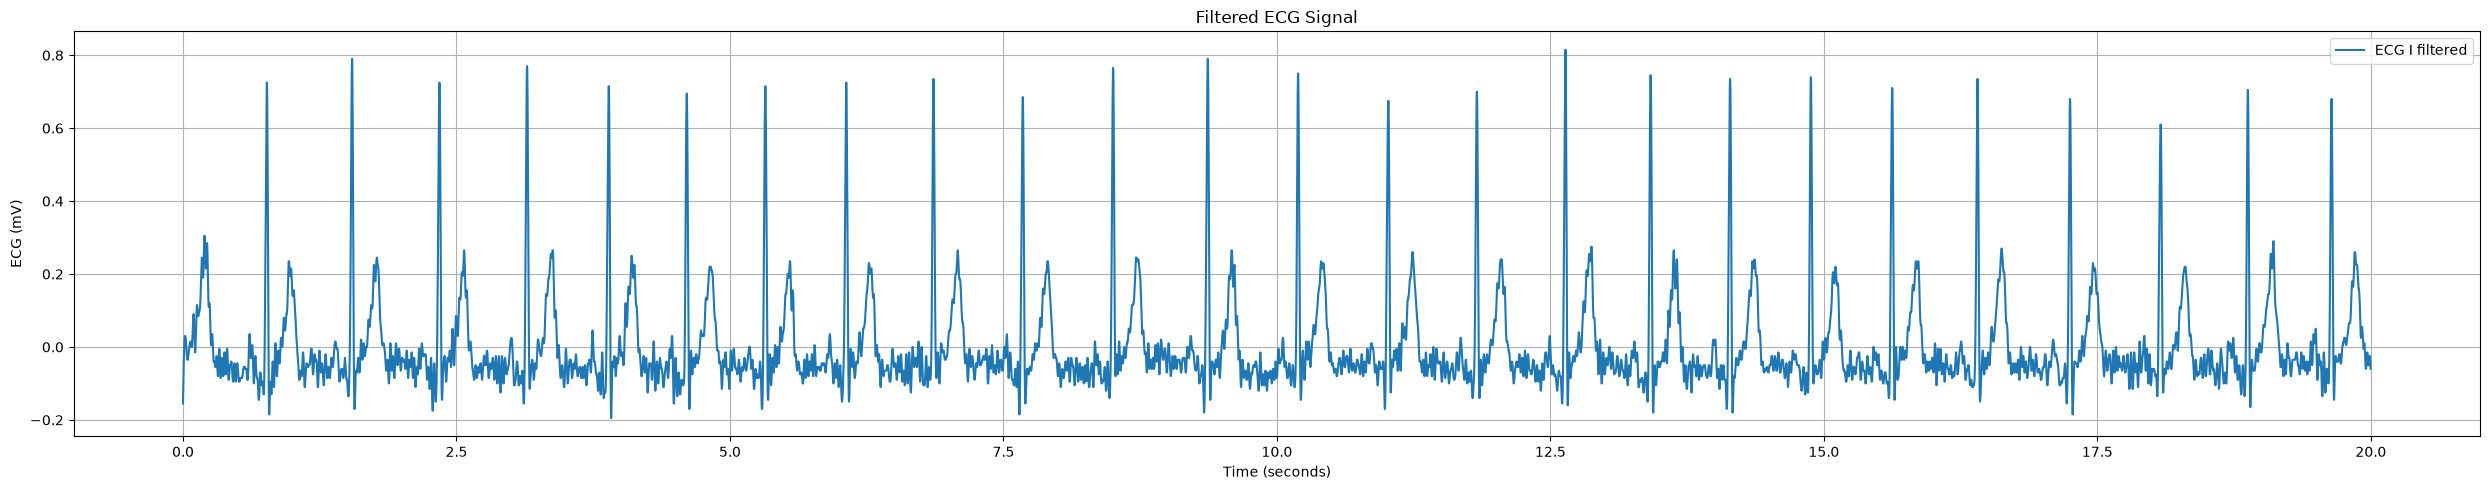

In [85]:
# Plot both signals
plt.figure(figsize=(25, 5))
plt.plot(df["Elapsed time"], df["ECG I"], label="ECG I")


plt.xlabel("Time (seconds)")
plt.ylabel("ECG (mV)")
plt.title("Original ECG Signal")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure(figsize=(25, 5))
plt.plot(df["Elapsed time"], df["ECG I filtered"], label="ECG I filtered")

plt.xlabel("Time (seconds)")
plt.ylabel("ECG (mV)")
plt.title("Filtered ECG Signal")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 2. The PSD shows a large peak at the 50Hz mark in the original ECG signal's PSD, which is later not present after filtering. This is the 50Hz powerline inteference being filtered out. Additionally, the filtering mostly kept frequencies from 0-50Hz, i.e. a low-pass filter was applied for the 0-50Hz range, which is precisely the range of frequencies of a typical ECG signal.

C:\Users\haina\AppData\Local\Temp\ipykernel_7652\2653200279.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


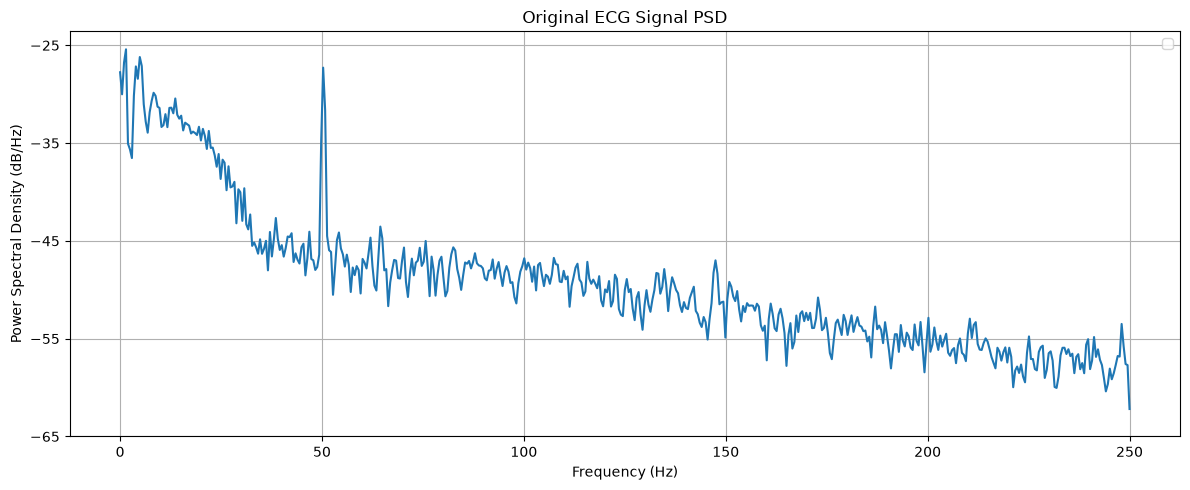

C:\Users\haina\AppData\Local\Temp\ipykernel_7652\2653200279.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


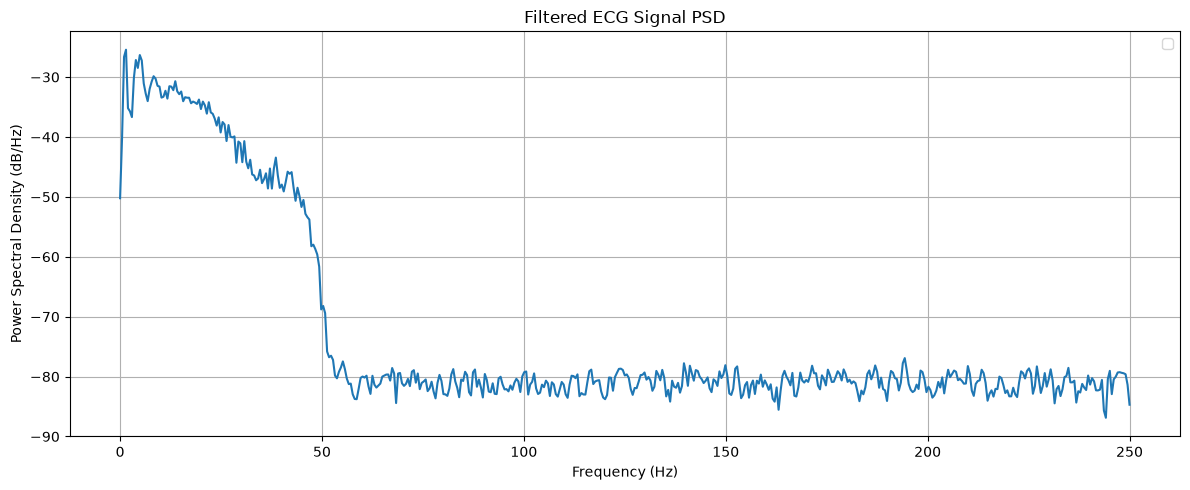

In [38]:
plt.figure(figsize=(12, 5))
plt.psd( df["ECG I"],Fs= 500, NFFT=1024)
plt.xlabel("Frequency (Hz)")
plt.title("Original ECG Signal PSD")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 5))
plt.psd( df["ECG I filtered"],Fs=500, NFFT=1024)
plt.xlabel("Frequency (Hz)")
plt.title("Filtered ECG Signal PSD")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 3. Limited signal to the first 5000 samples for better visualization.

## The algorithm can be seen to miss some R peaks and consequently the remaining peaks in a cycle, while it identifies all correctly for the filtered signal. Perhaps the small and rapid fluctations in the noise makes the sharp rise for the R peak undetectable for the algorithm. Therfore, while they are identifiable to the eye, perhaps it is computationally unclear for the algorithm if it is looking for a sharp slope for the R peak.

 ## However, once the algorithm has correctly identified an R peak in the unfiltered signal, the remaining peaks are identified correctly with high precision (the identifying lines match perfectly between unfiltered and filtered ECG). Thus, the hardest peak to identify for the algorithm is the R peak, the rest falls into place when it has been identified.

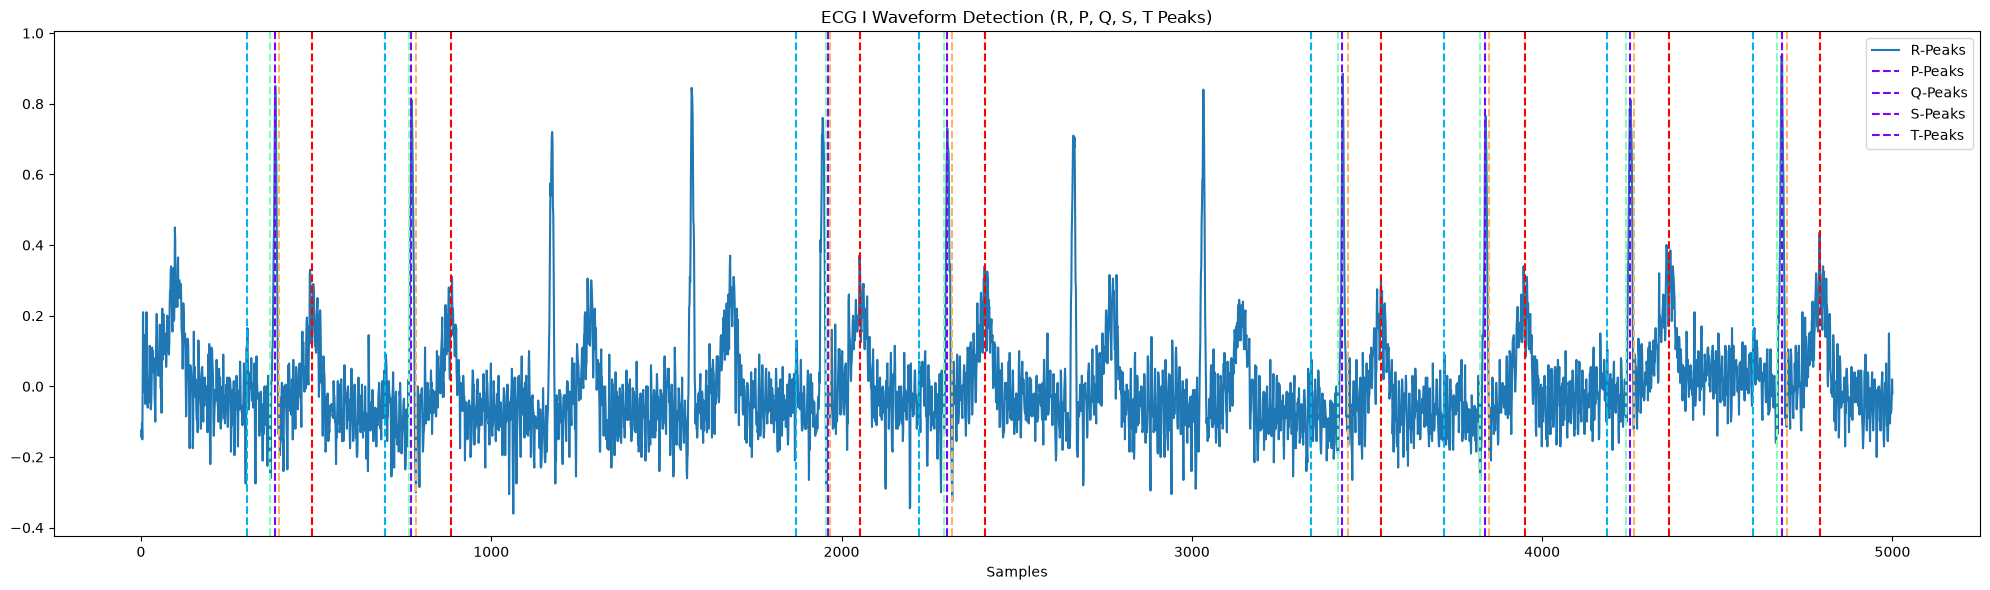

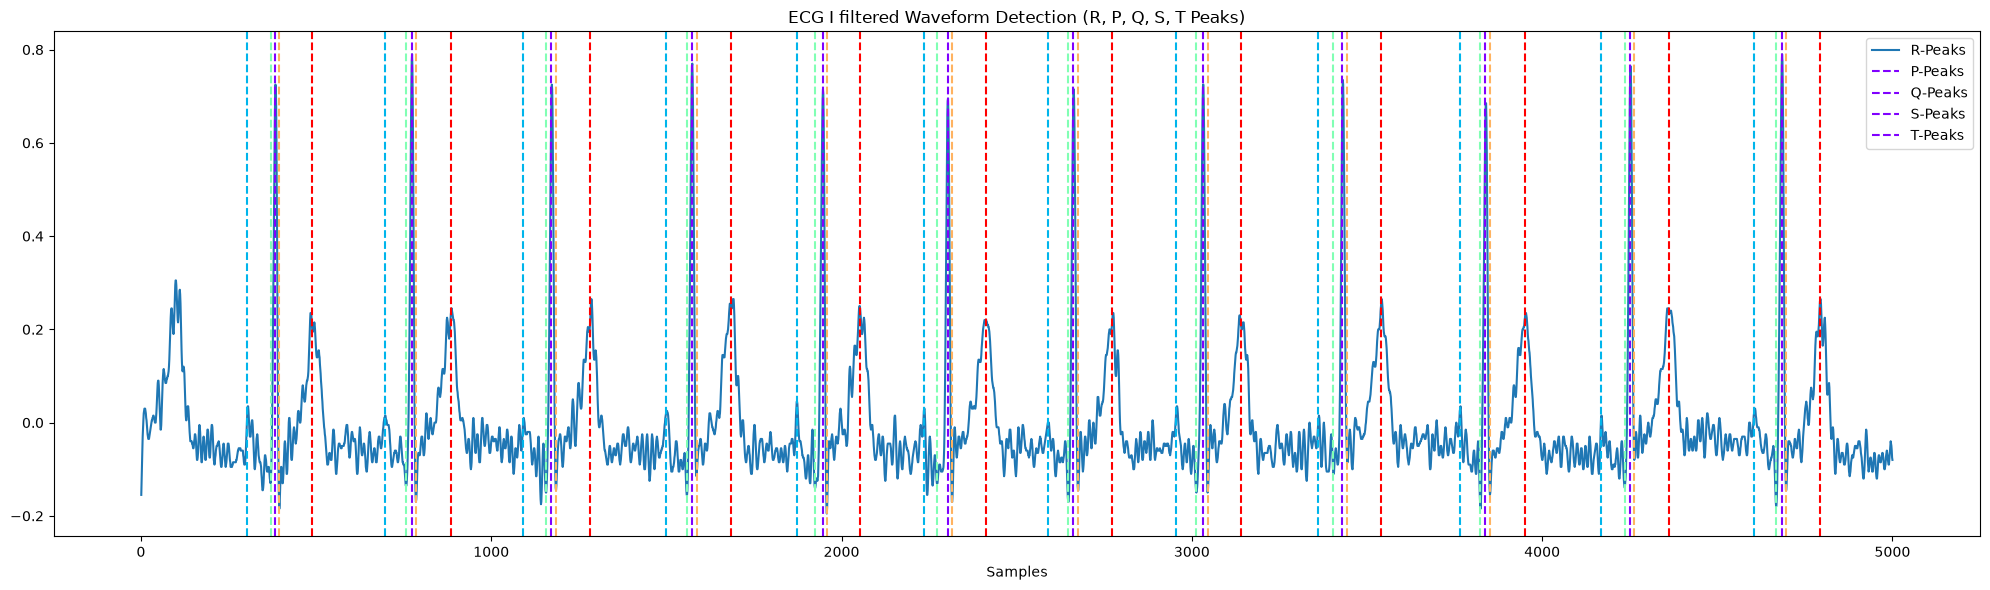

In [109]:
import matplotlib.pyplot as plt
import neurokit2 as nk


sampling_rate = 500  
for ecg in ["ECG I", "ECG I filtered"]:
    ecg_cleaned = df[ecg][0:5000]

    _, rpeaks = nk.ecg_peaks(ecg_cleaned, sampling_rate=sampling_rate)


    _, waves_peak = nk.ecg_delineate(
        ecg_cleaned,
        rpeaks,
        sampling_rate=sampling_rate,
    )

    # Extract onset indices for each wave type
    r_indices = rpeaks["ECG_R_Peaks"]
    p_indices = [x for x in waves_peak["ECG_P_Peaks"] if not np.isnan(x)]
    q_indices = [x for x in waves_peak["ECG_Q_Peaks"] if not np.isnan(x)]
    s_indices = [x for x in waves_peak["ECG_S_Peaks"] if not np.isnan(x)]
    t_indices = [x for x in waves_peak["ECG_T_Peaks"] if not np.isnan(x)]


    all_waveforms = [r_indices, p_indices, q_indices, s_indices, t_indices]

    fig = nk.events_plot(all_waveforms, signal=ecg_cleaned)
    fig.set_size_inches(20, 6, forward=True)

    plt.title(f"{ecg} Waveform Detection (R, P, Q, S, T Peaks)")
    plt.xlabel("Samples")


    plt.gca().legend(["R-Peaks", "P-Peaks", "Q-Peaks", "S-Peaks", "T-Peaks"])

    plt.tight_layout()
    plt.show()


In [ ]:
ecg_signal = df['ECG I']

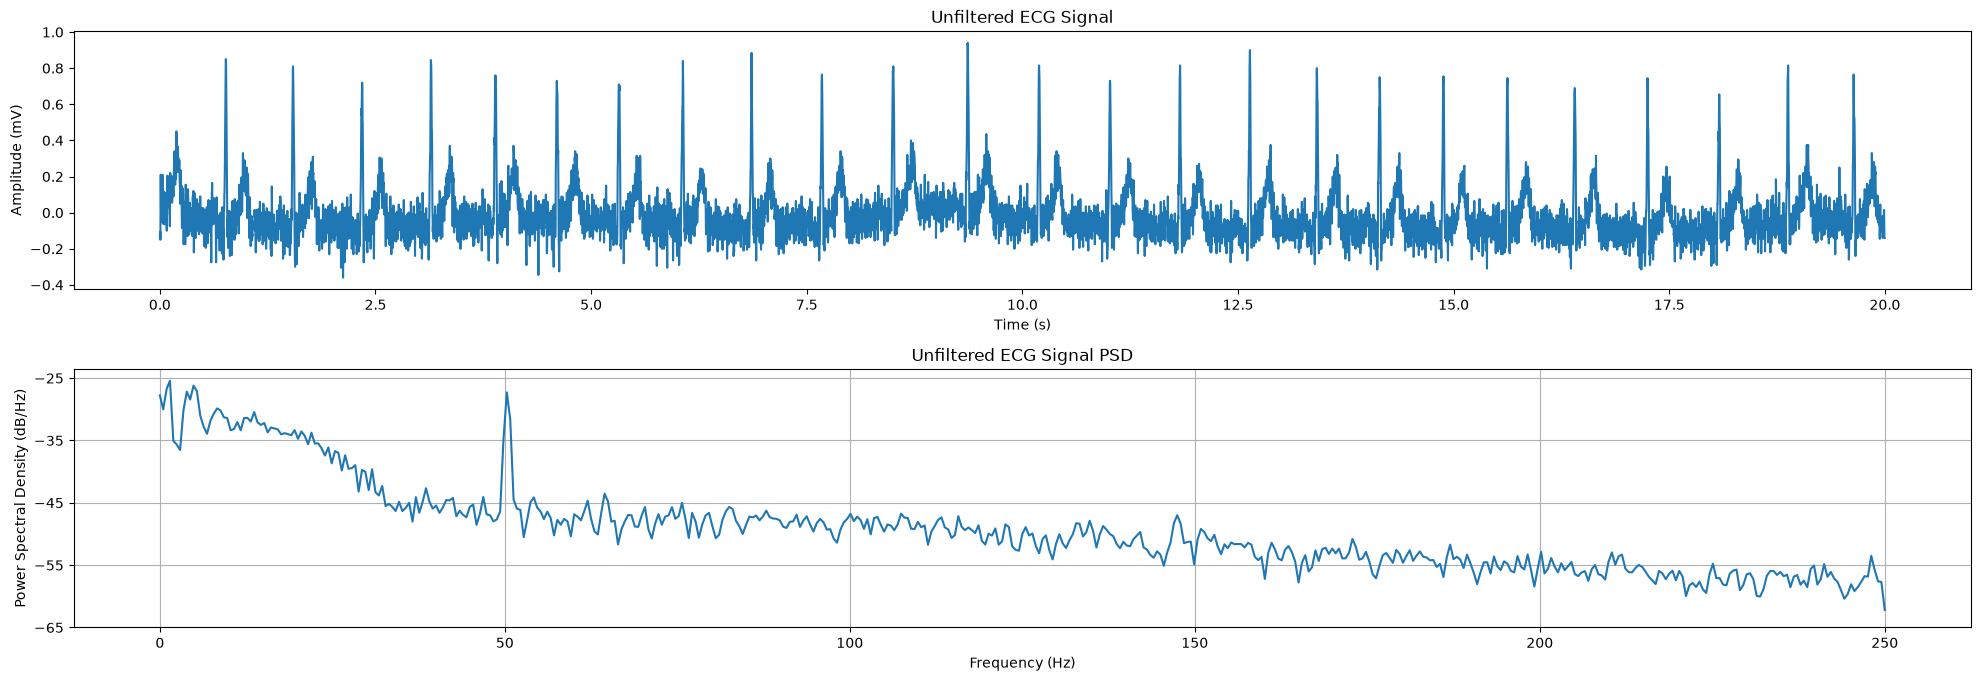

In [123]:
plt.figure(figsize=(20, 20))
plt.subplot(6, 1, 1)
plt.plot(df['Elapsed time'],ecg_signal,)
plt.title('Unfiltered ECG Signal')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude (mV)')


plt.subplot(6, 1, 2)
plt.psd( ecg_signal,Fs= 500, NFFT=1024)
plt.xlabel("Frequency (Hz)")
plt.title("Unfiltered ECG Signal PSD")

plt.tight_layout()